# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('traffic.csv')

In [3]:
df

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status
0,2024-09-18 17:00:00,D13,645.0,49.146283,25.226010,0.0,0,0.0,1.0,0.0,1.0,0.0,Normal
1,2023-07-08 17:00:00,D08,1321.0,39.828605,25.148830,0.0,0,0.0,0.0,1.0,1.4,0.0,Normal
2,2023-02-28 15:00:00,D17,1948.0,45.808054,27.286539,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal
3,2024-11-18 03:00:00,D11,416.0,54.326914,11.527077,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal
4,2024-08-31 10:00:00,D20,771.0,53.696496,14.911365,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
527127,2024-12-20 16:00:00,D10,2318.0,47.357095,25.810801,0.0,0,0.0,1.0,0.0,1.0,0.0,Normal
527128,2023-09-23 08:00:00,D17,1379.0,45.863525,23.274552,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
527129,2023-10-06 06:00:00,D06,1553.0,42.514541,36.689069,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal
527130,2024-03-25 00:00:00,D09,363.0,54.611336,4.999136,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 527132 entries, 0 to 527131
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   timestamp             527132 non-null  str    
 1   district_id           527132 non-null  str    
 2   traffic_volume        521867 non-null  float64
 3   average_speed_kmh     521867 non-null  float64
 4   congestion_index      521867 non-null  float64
 5   accident_count        521867 non-null  float64
 6   accident_flag         527132 non-null  int64  
 7   road_incident_count   521867 non-null  float64
 8   rush_hour_flag        521867 non-null  float64
 9   weekend_flag          521867 non-null  float64
 10  weather_impact_score  521867 non-null  float64
 11  special_event_impact  521867 non-null  float64
 12  sensor_status         527132 non-null  str    
dtypes: float64(9), int64(1), str(3)
memory usage: 66.4 MB


### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated composite key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated composite key
df[['timestamp', 'district_id']].duplicated().sum()

np.int64(1052)

In [7]:
df = df.drop_duplicates()

### Sorting data by districts then timestamps

In [8]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [9]:
df.describe()

,timestamp,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact
count,526080,520822.000000,520822.000000,520822.000000,520822.000000,526080.000000,520822.000000,520822.000000,520822.000000,520822.000000,520822.000000
mean,2024-07-01 23:30:00,1443.547822,46.558668,29.089288,0.035861,0.034814,0.086047,0.208444,0.285481,1.021081,0.007318
min,2023-01-01 00:00:00,47.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,2023-10-01 23:45:00,402.000000,41.194982,9.333610,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,2024-07-01 23:30:00,1287.000000,49.086562,23.792693,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,2025-04-01 23:15:00,2035.000000,55.422752,40.371386,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
max,2025-12-31 23:00:00,13504.000000,67.759866,120.000000,4.000000,1.000000,4.000000,1.000000,1.000000,2.000000,2.500000
std,NaN,1134.811056,11.634205,24.549297,0.191708,0.183309,0.294917,0.406196,0.451644,0.134871,0.112987


In [10]:
df['sensor_status'].unique()

<ArrowStringArray>
['Normal', 'Communication-Loss', 'Outage-Affected']
Length: 3, dtype: str

In [11]:
df['sensor_status'].value_counts()

sensor_status
Normal                520822
Communication-Loss      5174
Outage-Affected           84
Name: count, dtype: int64

In [12]:
df['accident_flag'].value_counts()

accident_flag
0    507765
1     18315
Name: count, dtype: int64

In [13]:
df['rush_hour_flag'].value_counts()

rush_hour_flag
0.0    412260
1.0    108562
Name: count, dtype: int64

In [14]:
df['weekend_flag'].value_counts()

weekend_flag
0.0    372137
1.0    148685
Name: count, dtype: int64

In [15]:
df[(df['accident_count'] > 0) & (df['accident_flag'] == 0)]

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status


In [16]:
df[(df['accident_count'] == 0) & (df['accident_flag'] == 1)]

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status


## Checking nulls

In [17]:
df.isnull().sum()
# Happened due to sensor issues

timestamp                  0
district_id                0
traffic_volume          5258
average_speed_kmh       5258
congestion_index        5258
accident_count          5258
accident_flag              0
road_incident_count     5258
rush_hour_flag          5258
weekend_flag            5258
weather_impact_score    5258
special_event_impact    5258
sensor_status              0
dtype: int64

In [18]:
# Check if the nulls is due to abnormal sensor state
sensor_cols = ['traffic_volume', 'average_speed_kmh', 'congestion_index','accident_count',
            'road_incident_count', 'rush_hour_flag', 'weekend_flag', 'weather_impact_score', 'special_event_impact']
for col in sensor_cols:
    print(f"{col}: {((df[col].isnull()) & (df['sensor_status'] == 'Normal')).sum()}")

# Since all the results are 0 that means There wasn't any observation where it was null while the sensor is normally working

traffic_volume: 0
average_speed_kmh: 0
congestion_index: 0
accident_count: 0
road_incident_count: 0
rush_hour_flag: 0
weekend_flag: 0
weather_impact_score: 0
special_event_impact: 0


In [19]:
# Check how many missing value happened in every detection cause of (Communication-Loss)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Communication-Loss')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")

traffic_volume: 5174 which is 98.40% of total null detections
average_speed_kmh: 5174 which is 98.40% of total null detections
congestion_index: 5174 which is 98.40% of total null detections
accident_count: 5174 which is 98.40% of total null detections
road_incident_count: 5174 which is 98.40% of total null detections
rush_hour_flag: 5174 which is 98.40% of total null detections
weekend_flag: 5174 which is 98.40% of total null detections
weather_impact_score: 5174 which is 98.40% of total null detections
special_event_impact: 5174 which is 98.40% of total null detections


In [20]:
# Check how many missing value happened in every detection cause of (Outage-Affected)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Outage-Affected')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")

traffic_volume: 84 which is 1.60% of total null detections
average_speed_kmh: 84 which is 1.60% of total null detections
congestion_index: 84 which is 1.60% of total null detections
accident_count: 84 which is 1.60% of total null detections
road_incident_count: 84 which is 1.60% of total null detections
rush_hour_flag: 84 which is 1.60% of total null detections
weekend_flag: 84 which is 1.60% of total null detections
weather_impact_score: 84 which is 1.60% of total null detections
special_event_impact: 84 which is 1.60% of total null detections


## Checking outliers

In [21]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return df[(df[column] < lower) | (df[column] > upper)]

continuous_cols = ['traffic_volume', 'average_speed_kmh', 'congestion_index',
    'accident_count', 'road_incident_count', 'weather_impact_score', 'special_event_impact']

for col in continuous_cols:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

traffic_volume: 6596, mean: 1443.55, above upper = 6596, below lower = 0
average_speed_kmh: 15904, mean: 46.56, above upper = 0, below lower = 15904
congestion_index: 13762, mean: 29.09, above upper = 13762, below lower = 0
accident_count: 18129, mean: 0.04, above upper = 18129, below lower = 0
road_incident_count: 42721, mean: 0.09, above upper = 42721, below lower = 0
weather_impact_score: 14164, mean: 1.02, above upper = 14164, below lower = 0
special_event_impact: 2326, mean: 0.01, above upper = 2326, below lower = 0


## Validating Outliers

### traffic_volume

In [22]:
traffic_outliers = find_outliers_iqr(df, 'traffic_volume')
traffic_outliers_suspisious = traffic_outliers[traffic_outliers['rush_hour_flag'] == 0]
traffic_outliers_suspisious

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status
1628,2023-03-09 20:00:00,D01,5070.0,24.492283,80.708076,0.0,0,0.0,0.0,0.0,1.0,1.8,Normal
1629,2023-03-09 21:00:00,D01,5025.0,27.728437,74.705672,1.0,1,1.0,0.0,0.0,1.0,1.8,Normal
8626,2023-12-26 10:00:00,D01,7268.0,11.401037,115.221632,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
8627,2023-12-26 11:00:00,D01,7577.0,7.484049,113.936034,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
8628,2023-12-26 12:00:00,D01,7948.0,5.000000,120.000000,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
445018,2025-10-03 10:00:00,D17,4750.0,26.209096,71.072961,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
445020,2025-10-03 12:00:00,D17,4490.0,25.355951,70.067275,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
445023,2025-10-03 15:00:00,D17,4723.0,23.703886,72.984535,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal
451935,2023-07-18 15:00:00,D18,4504.0,19.744165,95.807306,0.0,0,0.0,0.0,0.0,1.0,2.5,Normal


### average_speed_kmh

In [23]:
speed_outliers = find_outliers_iqr(df, 'average_speed_kmh')
speed_outliers_suspisious = speed_outliers[speed_outliers['congestion_index'] < df['congestion_index'].mean()]
speed_outliers_suspisious

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status


### congestion_index

In [24]:
congestion_outliers = find_outliers_iqr(df, 'congestion_index')
congestion_outliers_suspisious = congestion_outliers[congestion_outliers['traffic_volume'] < df['traffic_volume'].mean()]
congestion_outliers_suspisious

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status
265054,2023-03-25 22:00:00,D11,1378.0,5.0,119.106044,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
265408,2023-04-09 16:00:00,D11,1404.0,5.0,118.275406,1.0,1,1.0,0.0,1.0,2.0,0.0,Normal
267249,2023-06-25 09:00:00,D11,1410.0,5.0,115.776076,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
267250,2023-06-25 10:00:00,D11,1443.0,5.0,118.957875,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
267251,2023-06-25 11:00:00,D11,1368.0,5.0,115.544328,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
287552,2025-10-18 08:00:00,D11,1202.0,5.0,95.793761,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
287553,2025-10-18 09:00:00,D11,1366.0,5.0,116.099930,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
288558,2025-11-29 06:00:00,D11,1350.0,5.0,114.648006,0.0,0,0.0,0.0,1.0,2.0,0.0,Normal
288559,2025-11-29 07:00:00,D11,1443.0,5.0,117.939596,1.0,1,1.0,0.0,1.0,2.0,0.0,Normal


### accident_count

In [25]:
accident_outliers = find_outliers_iqr(df, 'accident_count')
accident_outliers_suspisious = accident_outliers[accident_outliers['accident_flag'] == 0]
accident_outliers_suspisious

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status


### Road incident count

In [26]:
incident_outliers = find_outliers_iqr(df, 'road_incident_count')
incident_outliers

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status
18,2023-01-01 18:00:00,D01,1990.0,47.868217,33.358044,0.0,0,1.0,0.0,1.0,1.0,0.0,Normal
31,2023-01-02 07:00:00,D01,5080.0,22.001203,82.835357,1.0,1,1.0,1.0,0.0,1.0,0.0,Normal
33,2023-01-02 09:00:00,D01,4927.0,27.436059,74.977724,0.0,0,1.0,1.0,0.0,1.0,0.0,Normal
35,2023-01-02 11:00:00,D01,2858.0,42.092438,41.911615,1.0,1,1.0,0.0,0.0,1.0,0.0,Normal
36,2023-01-02 12:00:00,D01,2981.0,40.115342,43.673126,0.0,0,2.0,0.0,0.0,1.0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
526030,2025-12-29 22:00:00,D20,1181.0,48.995683,25.922118,1.0,1,1.0,0.0,0.0,1.0,0.0,Normal
526036,2025-12-30 04:00:00,D20,220.0,59.878363,2.385011,0.0,0,1.0,0.0,0.0,1.0,0.0,Normal
526049,2025-12-30 17:00:00,D20,2066.0,5.000000,90.571839,1.0,1,1.0,1.0,0.0,2.0,0.0,Normal
526051,2025-12-30 19:00:00,D20,2094.0,22.497917,66.855416,1.0,1,1.0,1.0,0.0,1.4,0.0,Normal


# Important KPIs

## Average congestion index per district

In [27]:
districts = pd.read_csv('districts.csv')
districts_traffic = districts.merge(df, on='district_id')

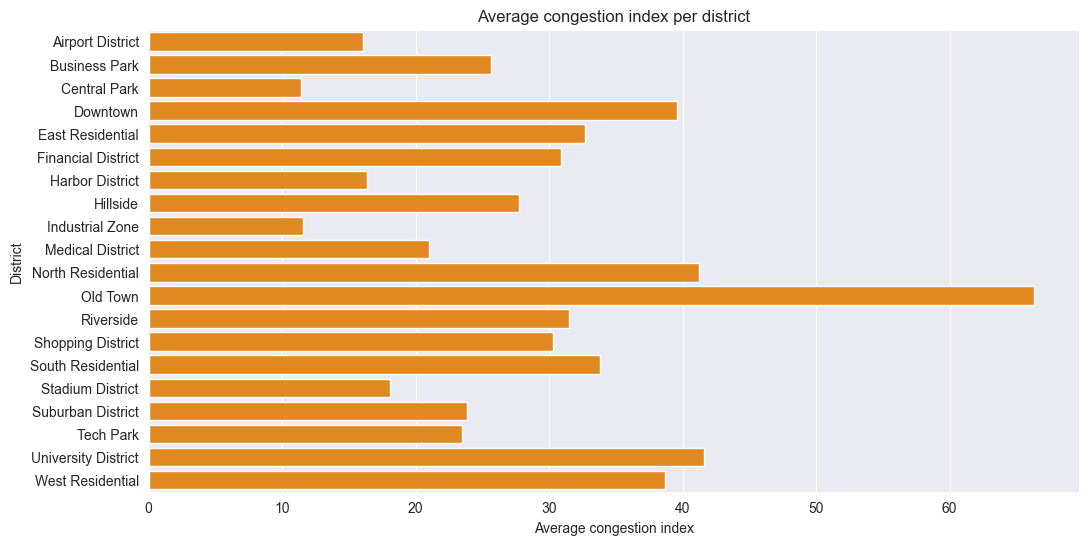

In [28]:
average_congestion = districts_traffic.groupby('district_name').agg(congestion_index_avg = ('congestion_index', 'mean'))

sns.barplot(average_congestion, y='district_name', x='congestion_index_avg', color='darkorange')
plt.xlabel('Average congestion index')
plt.ylabel('District')
plt.title('Average congestion index per district')

plt.show()

## Average traffic speed per district

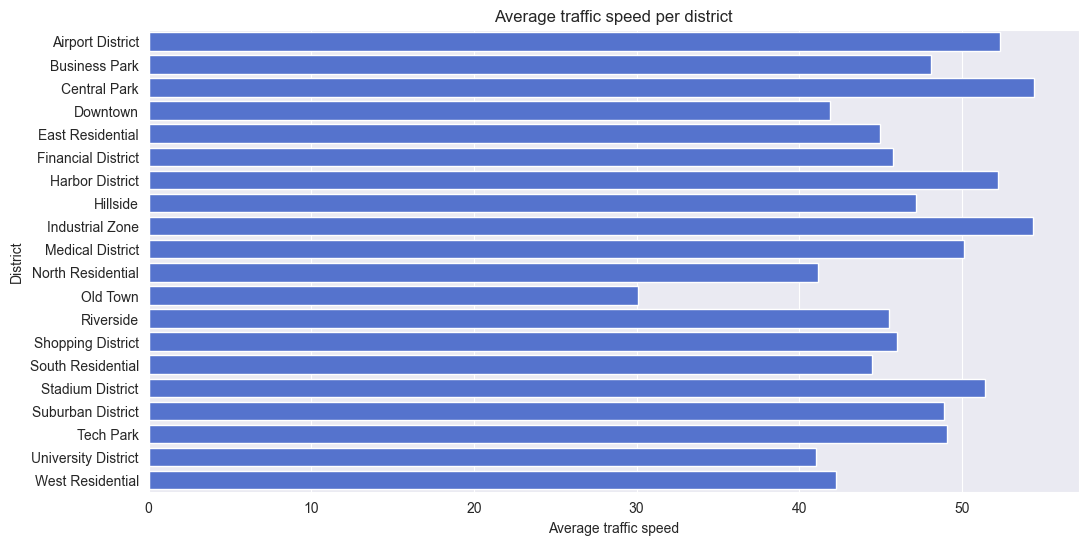

In [29]:
average_speed = districts_traffic.groupby('district_name').agg(speed_avg = ('average_speed_kmh', 'mean'))

sns.barplot(average_speed, y='district_name', x='speed_avg', color='royalblue')
plt.xlabel('Average traffic speed')
plt.ylabel('District')
plt.title('Average traffic speed per district')

plt.show()

## Accident rate per district

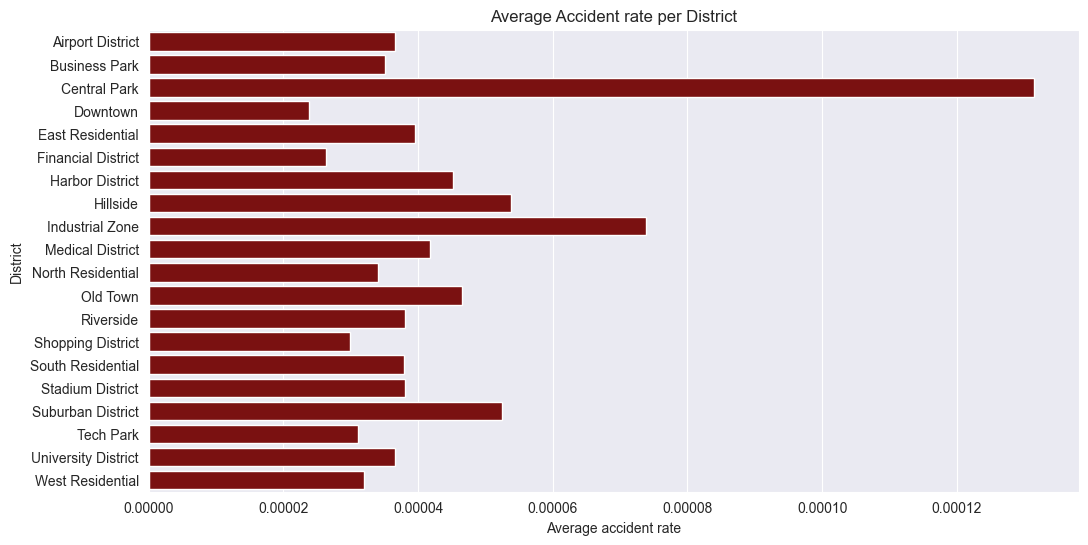

In [30]:
districts_traffic['accident_rate'] = districts_traffic['accident_count'] / districts_traffic['traffic_volume']

avg_accident = districts_traffic.groupby('district_name').agg(avg_accident_rate = ('accident_rate', 'mean'))

sns.barplot(avg_accident, y='district_name', x='avg_accident_rate', color='darkred')
plt.xlabel('Average accident rate')
plt.ylabel('District')
plt.title('Average Accident rate per District')

plt.show()

## Incident rate per district

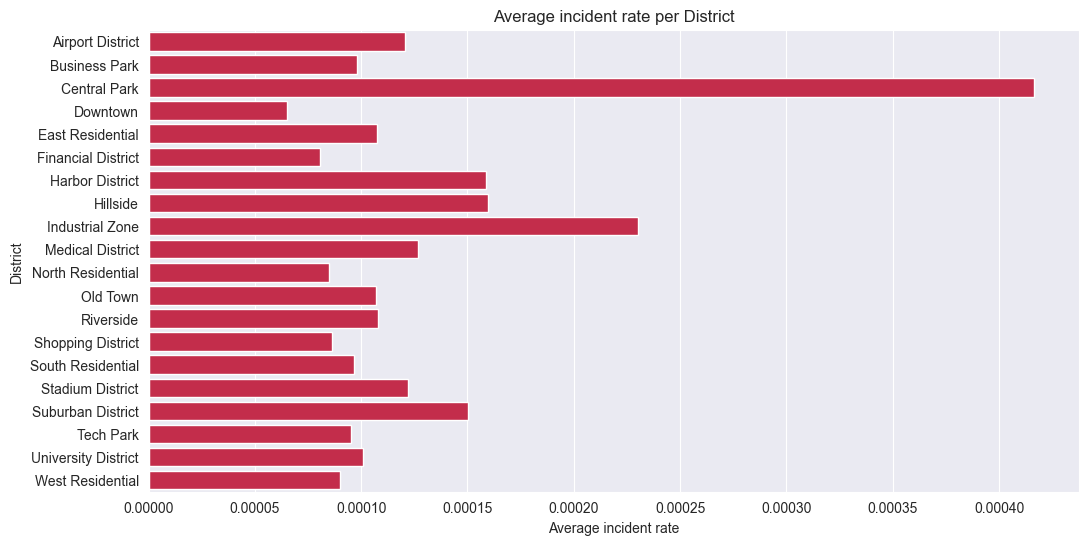

In [31]:
districts_traffic['incident_rate'] = districts_traffic['road_incident_count'] / districts_traffic['traffic_volume']

avg_incident = districts_traffic.groupby('district_name').agg(avg_incident_rate = ('incident_rate', 'mean'))

sns.barplot(avg_incident, y='district_name', x='avg_incident_rate', color='crimson')
plt.xlabel('Average incident rate')
plt.ylabel('District')
plt.title('Average incident rate per District')

plt.show()

## Rush hour traffic performance

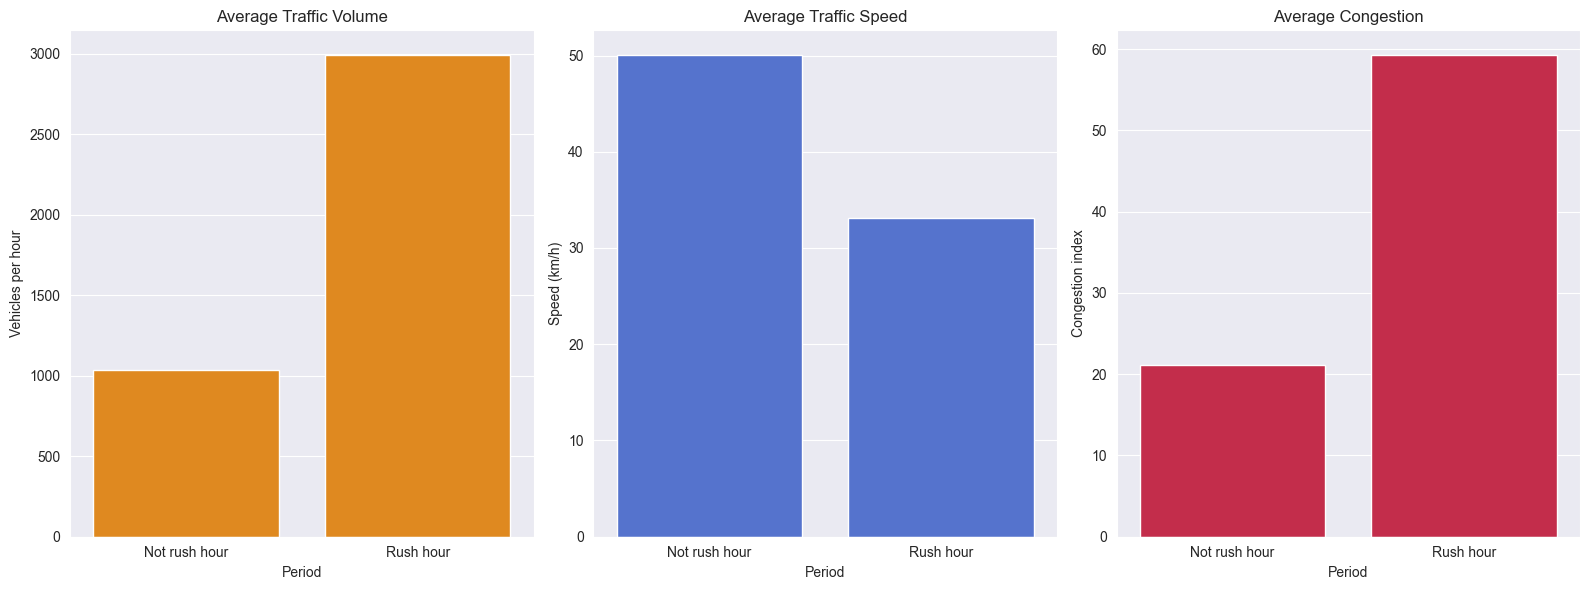

In [32]:
rush_hour_performance = df.groupby('rush_hour_flag').agg(
    average_traffic_volume=('traffic_volume', 'mean'),
    average_speed=('average_speed_kmh', 'mean'),
    average_congestion=('congestion_index', 'mean')
).reset_index()
rush_hour_performance['period'] = rush_hour_performance['rush_hour_flag'].map({0: 'Not rush hour', 1: 'Rush hour'})

fig, ax = plt.subplots(1, 3, figsize=(16, 6))

sns.barplot(rush_hour_performance, x='period', y='average_traffic_volume', color='darkorange', ax=ax[0])
ax[0].set_title('Average Traffic Volume')
ax[0].set_xlabel('Period')
ax[0].set_ylabel('Vehicles per hour')

sns.barplot(rush_hour_performance, x='period', y='average_speed', color='royalblue', ax=ax[1])
ax[1].set_title('Average Traffic Speed')
ax[1].set_xlabel('Period')
ax[1].set_ylabel('Speed (km/h)')

sns.barplot(rush_hour_performance, x='period', y='average_congestion', color='crimson', ax=ax[2])
ax[2].set_title('Average Congestion')
ax[2].set_xlabel('Period')
ax[2].set_ylabel('Congestion index')

plt.tight_layout()
plt.show()

# Data Cleaning

## Handling Nulls

In [33]:
cleaned_traffic = df
cleaned_traffic.ffill(inplace=True)
cleaned_traffic.bfill(inplace=True)

,timestamp,district_id,traffic_volume,average_speed_kmh,congestion_index,accident_count,accident_flag,road_incident_count,rush_hour_flag,weekend_flag,weather_impact_score,special_event_impact,sensor_status
0,2023-01-01 00:00:00,D01,441.0,57.620606,6.675445,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
1,2023-01-01 01:00:00,D01,384.0,58.598533,7.131570,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
2,2023-01-01 02:00:00,D01,400.0,57.321975,8.904242,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
3,2023-01-01 03:00:00,D01,424.0,53.094577,6.097470,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
4,2023-01-01 04:00:00,D01,396.0,61.069140,2.067407,0.0,0,0.0,0.0,1.0,1.0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 19:00:00,D20,2078.0,34.459541,43.179529,0.0,0,0.0,1.0,0.0,1.0,0.0,Normal
526076,2025-12-31 20:00:00,D20,1077.0,49.470012,22.549510,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal
526077,2025-12-31 21:00:00,D20,1147.0,47.734192,31.022348,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal
526078,2025-12-31 22:00:00,D20,1198.0,45.562684,31.114597,0.0,0,0.0,0.0,0.0,1.0,0.0,Normal


In [34]:
cleaned_traffic.to_csv('data/cleaned_traffic.csv', index=False)